# 2. Results

All models on the same test period. Differences smaller than the bootstrap interval or the range over seeds are not claims; three seeds give a range, not a confidence interval.

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
fraud = load_results('results_fraud.csv')
account = load_results('results_account.csv')
print('config hash:', fraud['config_hash'].unique())

config hash: <StringArray>
['0a4fb49dd420']
Length: 1, dtype: str


In [2]:
metrics = ['pr_auc', 'roc_auc', 'recall_at_fpr', 'cost', 'brier', 'ece']
seed_summary(fraud, metrics).round(3)

,model,pr_auc_mean,roc_auc_mean,recall_at_fpr_mean,cost_mean,brier_mean,ece_mean,pr_auc_min,roc_auc_min,recall_at_fpr_min,cost_min,brier_min,ece_min,pr_auc_max,roc_auc_max,recall_at_fpr_max,cost_max,brier_max,ece_max
0,fraud_only,0.349,0.840,0.307,150521.539,0.071,0.197,0.345,0.835,0.298,145854.148,0.070,0.196,0.358,0.848,0.317,158512.453,0.072,0.199
1,history_stable_tabular,0.465,0.885,0.434,139487.131,0.025,0.005,0.456,0.881,0.428,129892.775,0.025,0.004,0.476,0.888,0.441,144652.160,0.025,0.005
2,history_tabular,0.446,0.884,0.415,136641.191,0.025,0.006,0.438,0.883,0.405,134936.842,0.025,0.005,0.452,0.886,0.426,138535.991,0.026,0.006
3,multitask,0.341,0.836,0.308,154641.457,0.072,0.200,0.334,0.830,0.289,147094.447,0.068,0.191,0.350,0.839,0.321,160627.362,0.075,0.207
4,naive_tabular,0.462,0.889,0.425,134285.125,0.025,0.006,0.449,0.886,0.422,132499.877,0.025,0.006,0.469,0.891,0.429,137007.278,0.025,0.007
5,no_graph,0.335,0.819,0.302,172599.068,0.063,0.172,0.328,0.808,0.291,160299.950,0.059,0.161,0.344,0.827,0.318,180143.909,0.066,0.181


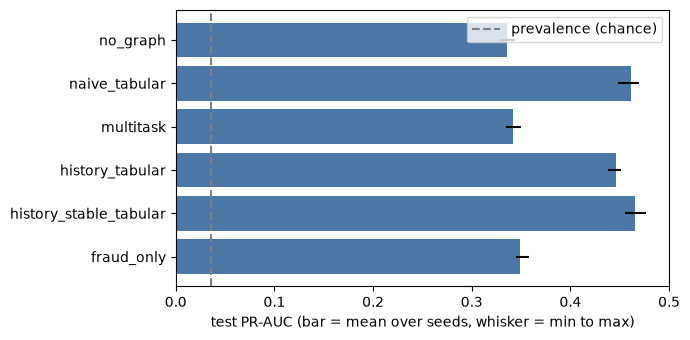

In [3]:
plot_pr_auc(fraud);

## Alert budgets

Recall, precision and the share of fraud *value* caught when only the top 0.5%, 1% or 5% of transactions can be reviewed.

In [4]:
cols = [c for c in fraud.columns if c.split('@')[0] in ('recall', 'precision', 'amount_recall') and '@' in c]
fraud.groupby('model')[cols].mean().round(3)

,recall@0.005,precision@0.005,amount_recall@0.005,recall@0.01,precision@0.01,amount_recall@0.01,recall@0.05,precision@0.05,amount_recall@0.05
model,,,,,,,,,
fraud_only,0.106,0.768,0.039,0.188,0.679,0.089,0.432,0.312,0.366
history_stable_tabular,0.119,0.858,0.075,0.230,0.831,0.131,0.531,0.384,0.455
history_tabular,0.116,0.841,0.073,0.228,0.823,0.128,0.521,0.377,0.441
multitask,0.110,0.797,0.037,0.194,0.701,0.084,0.408,0.295,0.352
naive_tabular,0.116,0.838,0.071,0.229,0.829,0.125,0.530,0.383,0.472
no_graph,0.102,0.738,0.045,0.182,0.659,0.096,0.431,0.312,0.357


## Cost

Expected cost uses an assumed review cost per false alert (see the config); compare each model with flagging nothing.

In [5]:
fraud.groupby('model')[['cost', 'cost_flag_none', 'cost_flag_all']].mean().round(0)

,cost,cost_flag_none,cost_flag_all
model,,,
fraud_only,150522.0,370374.0,320990.0
history_stable_tabular,139487.0,370374.0,320990.0
history_tabular,136641.0,370374.0,320990.0
multitask,154641.0,370374.0,320990.0
naive_tabular,134285.0,370374.0,320990.0
no_graph,172599.0,370374.0,320990.0


## Account-risk head and ablations

In [6]:
seed_summary(account, ['pr_auc', 'roc_auc']).round(3)

,model,pr_auc_mean,roc_auc_mean,pr_auc_min,roc_auc_min,pr_auc_max,roc_auc_max
0,account_only,0.215,0.777,0.210,0.770,0.224,0.786
1,hgb_user_aggregates,0.133,0.675,0.116,0.659,0.151,0.683
2,mean_fraud_score,0.452,0.857,0.439,0.850,0.471,0.862
3,multitask,0.247,0.769,0.226,0.753,0.263,0.782


## Over time and calibration

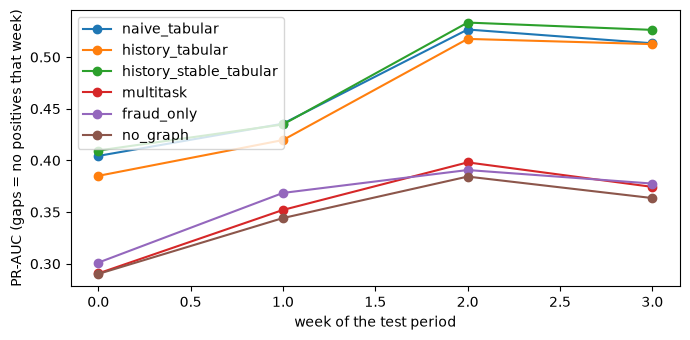

In [7]:
plot_weekly(load_results('results_weekly.csv'));

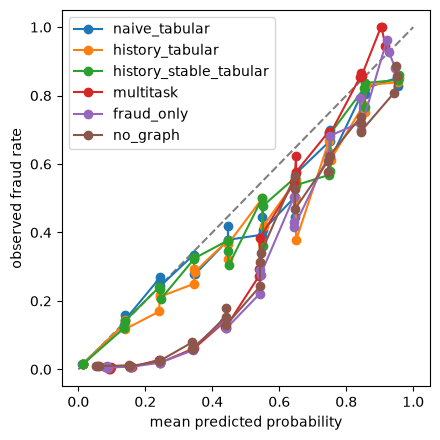

In [8]:
plot_calibration(load_results('calibration.csv'));